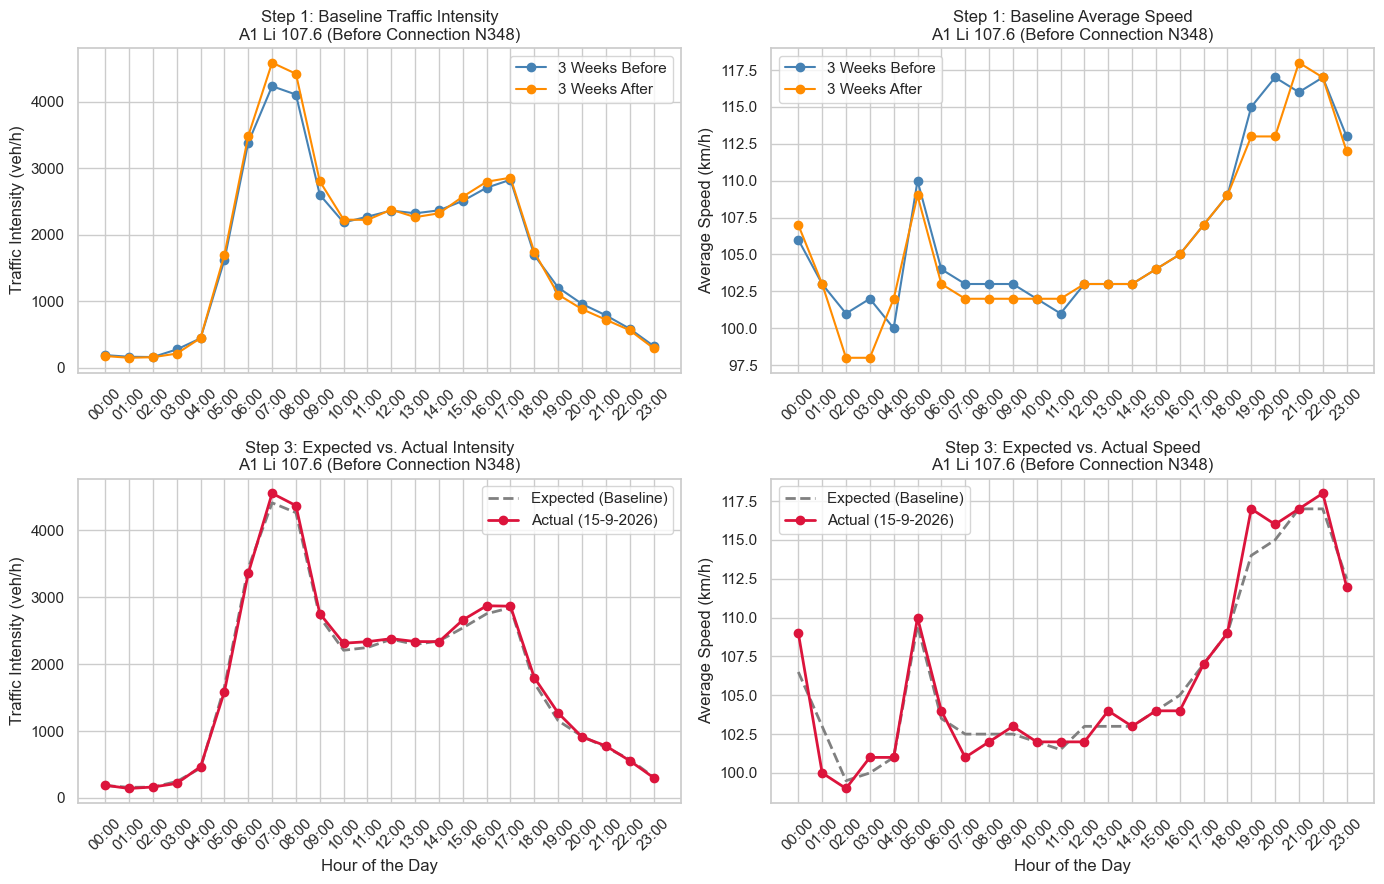

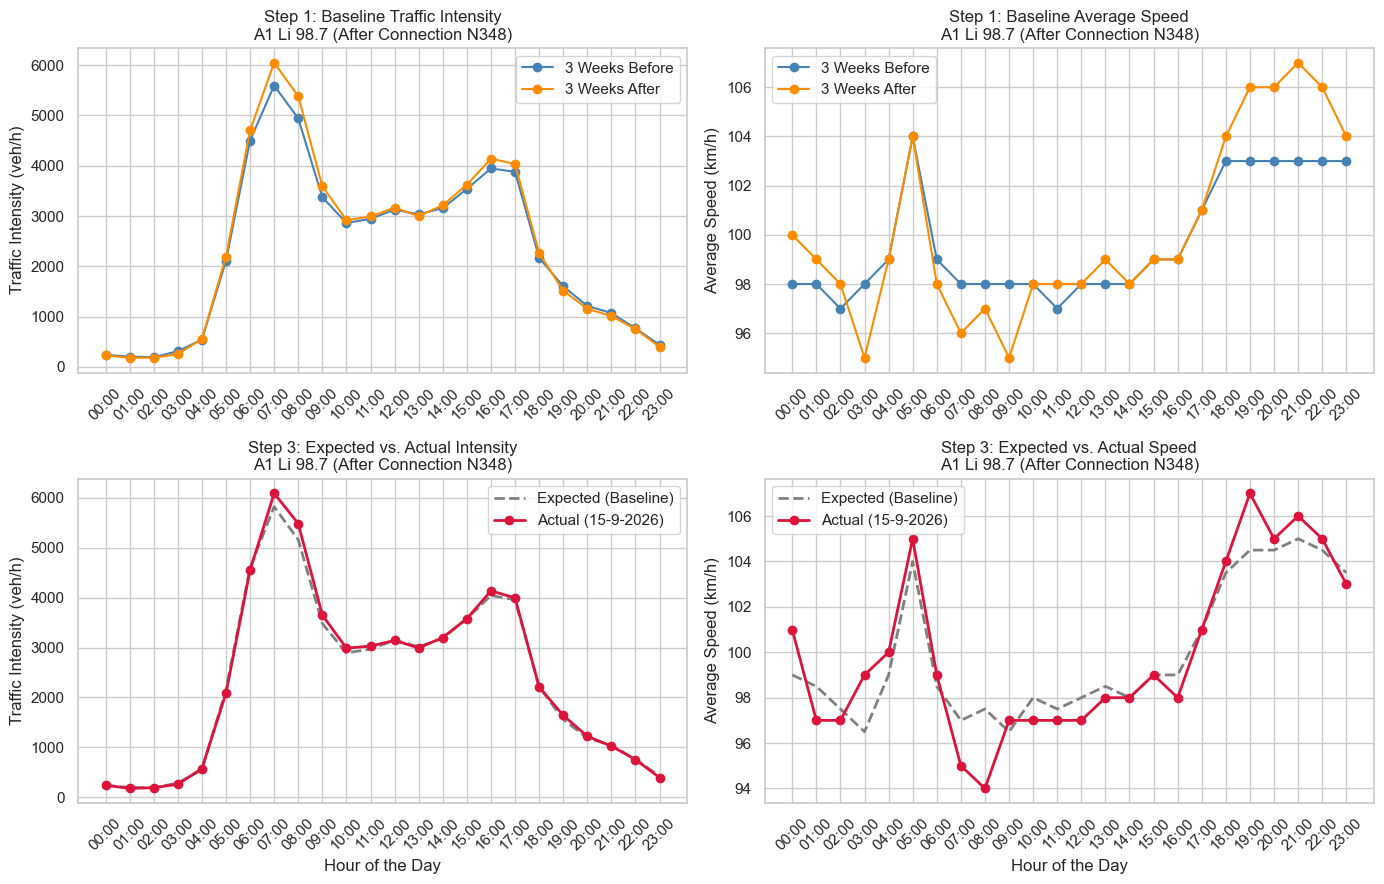

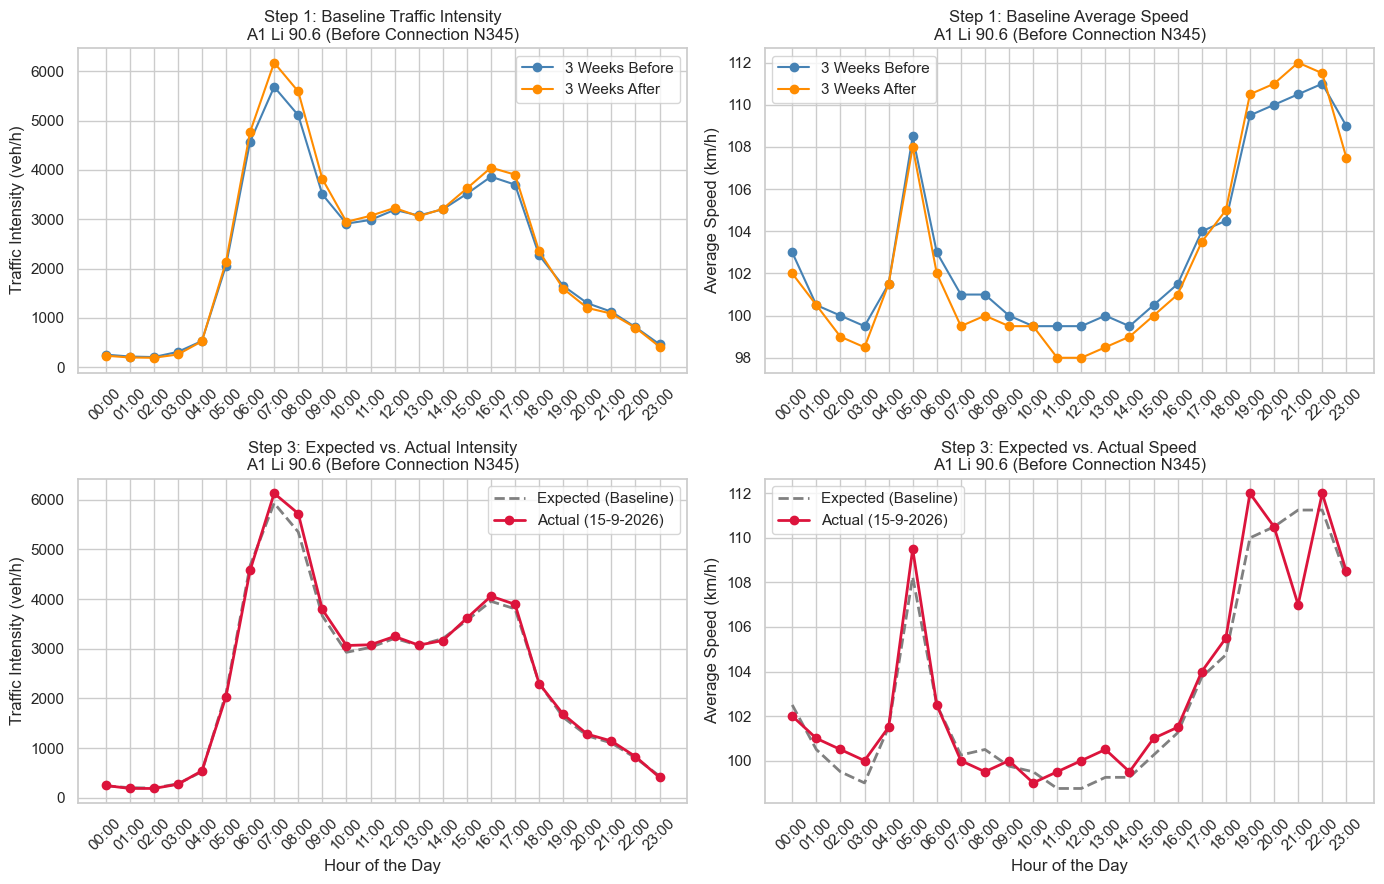

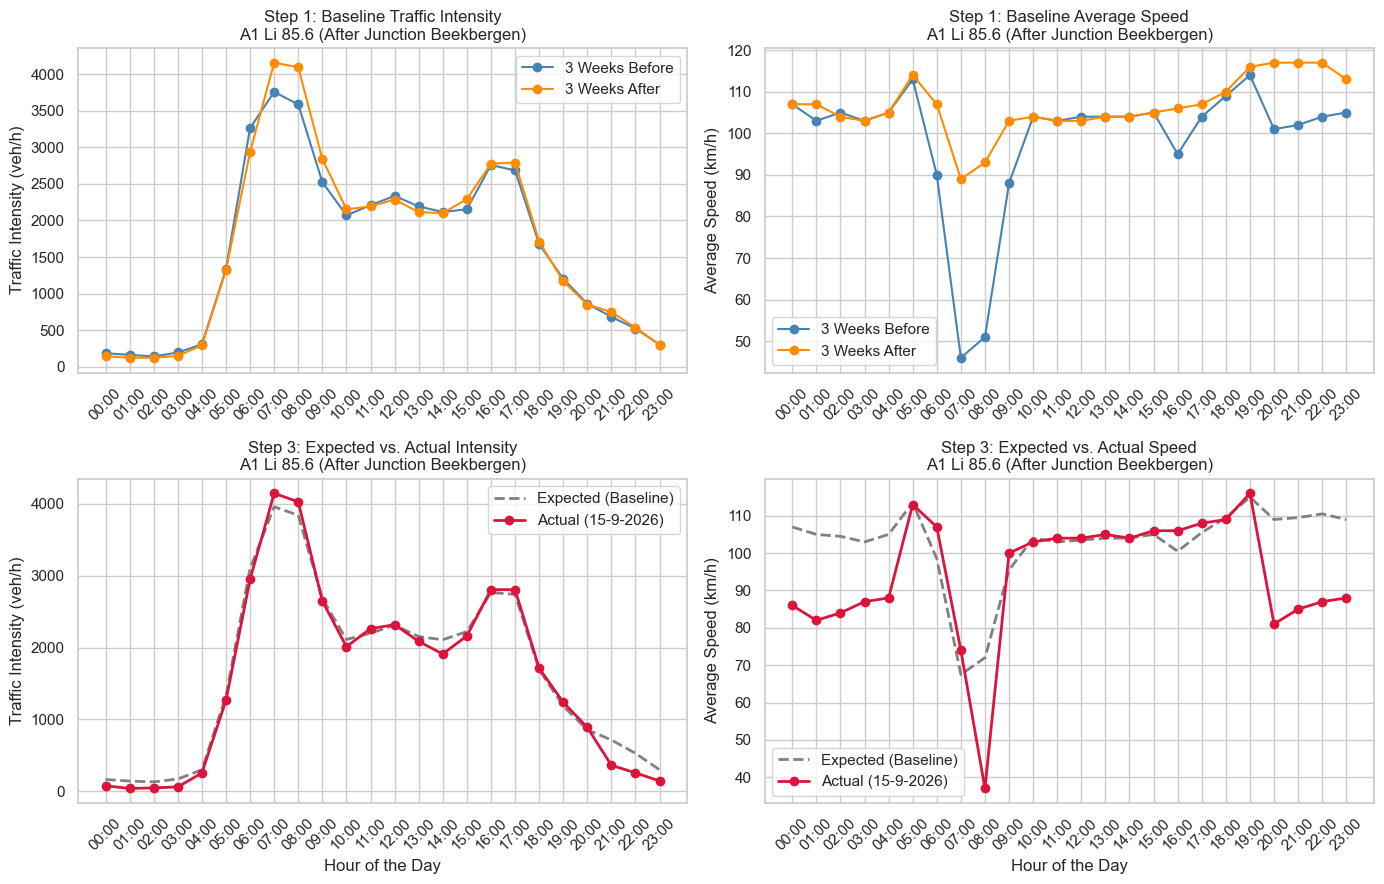

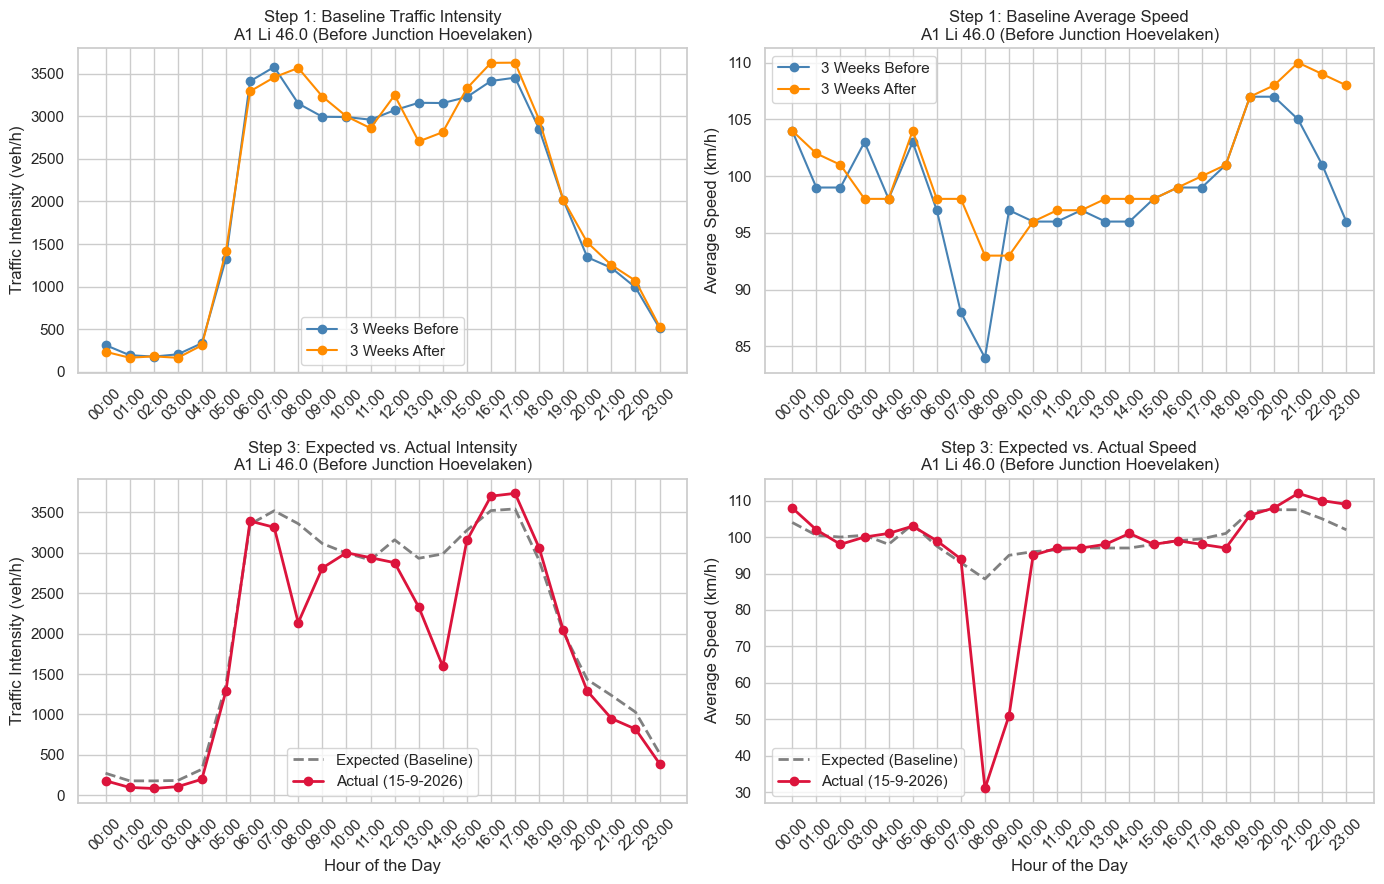

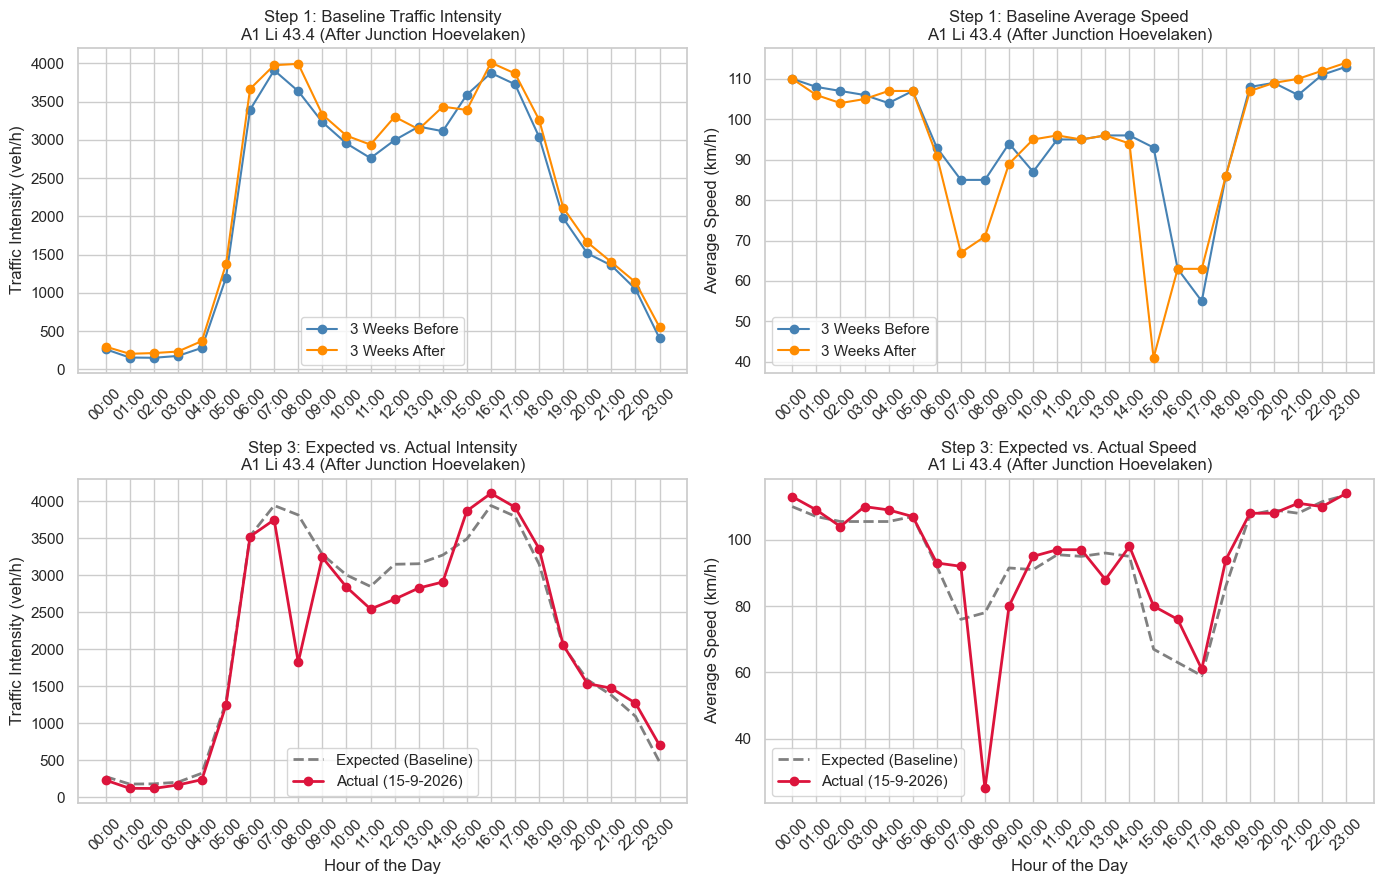

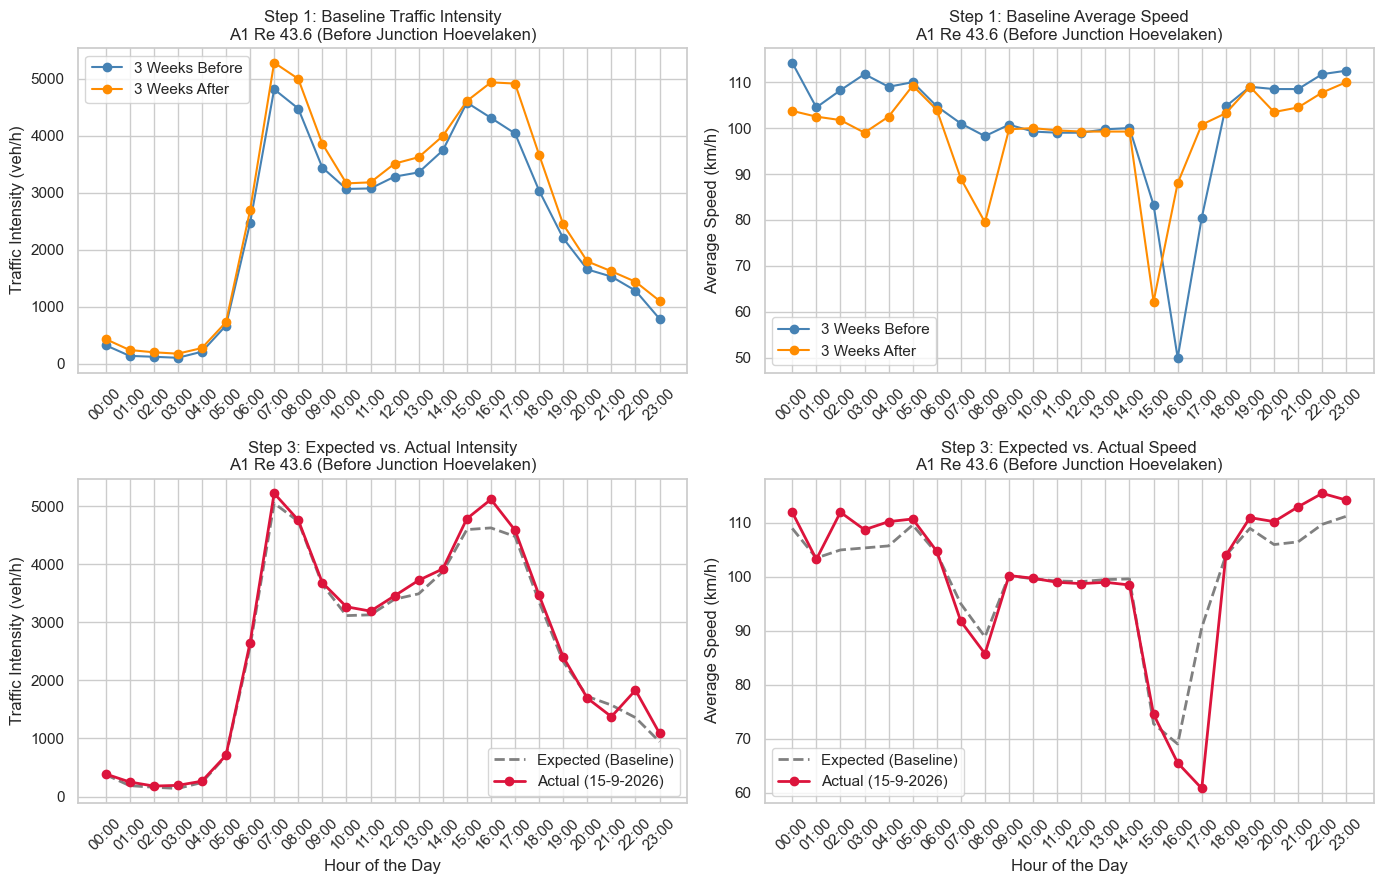

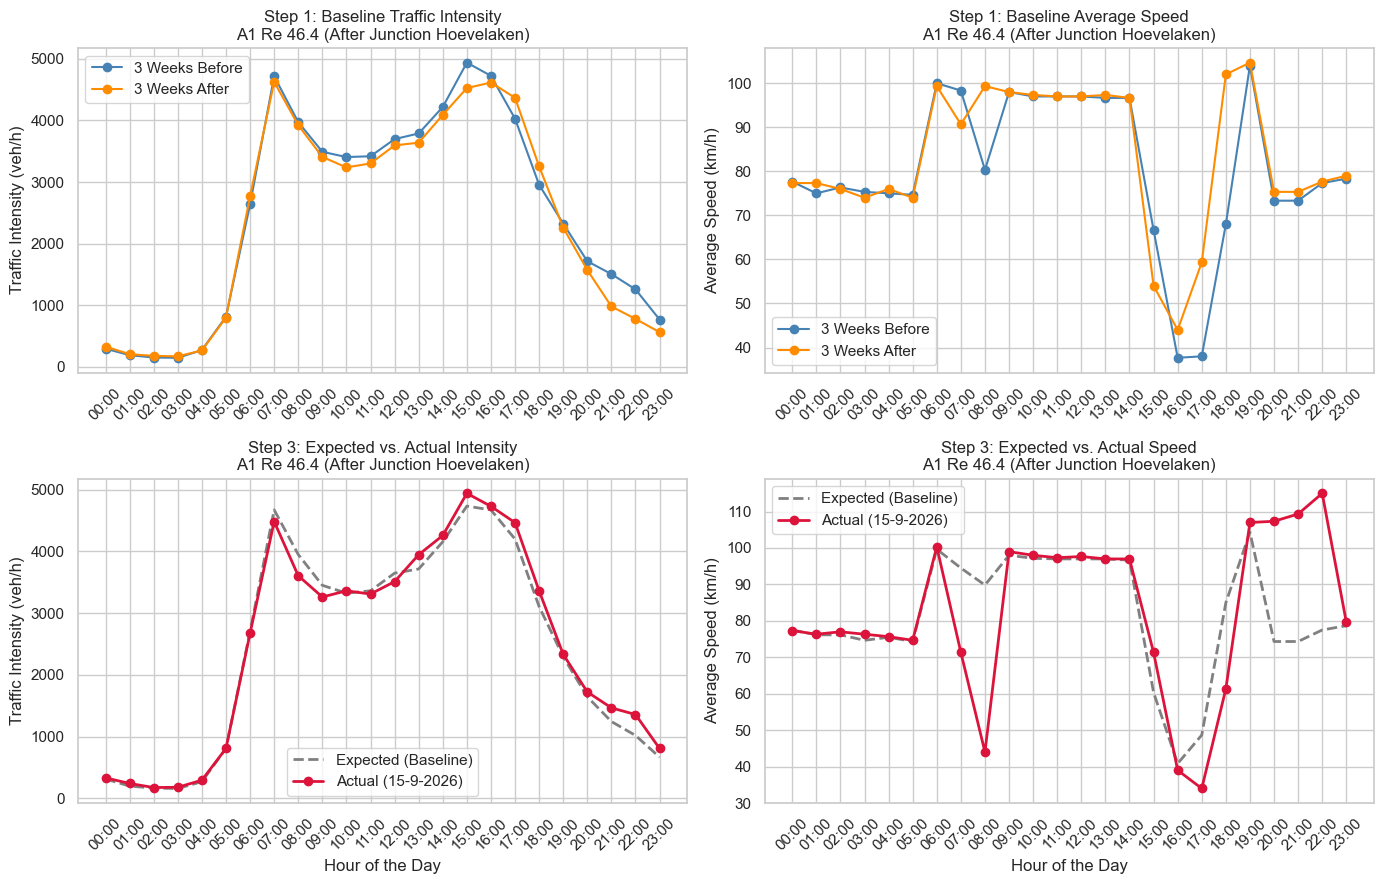

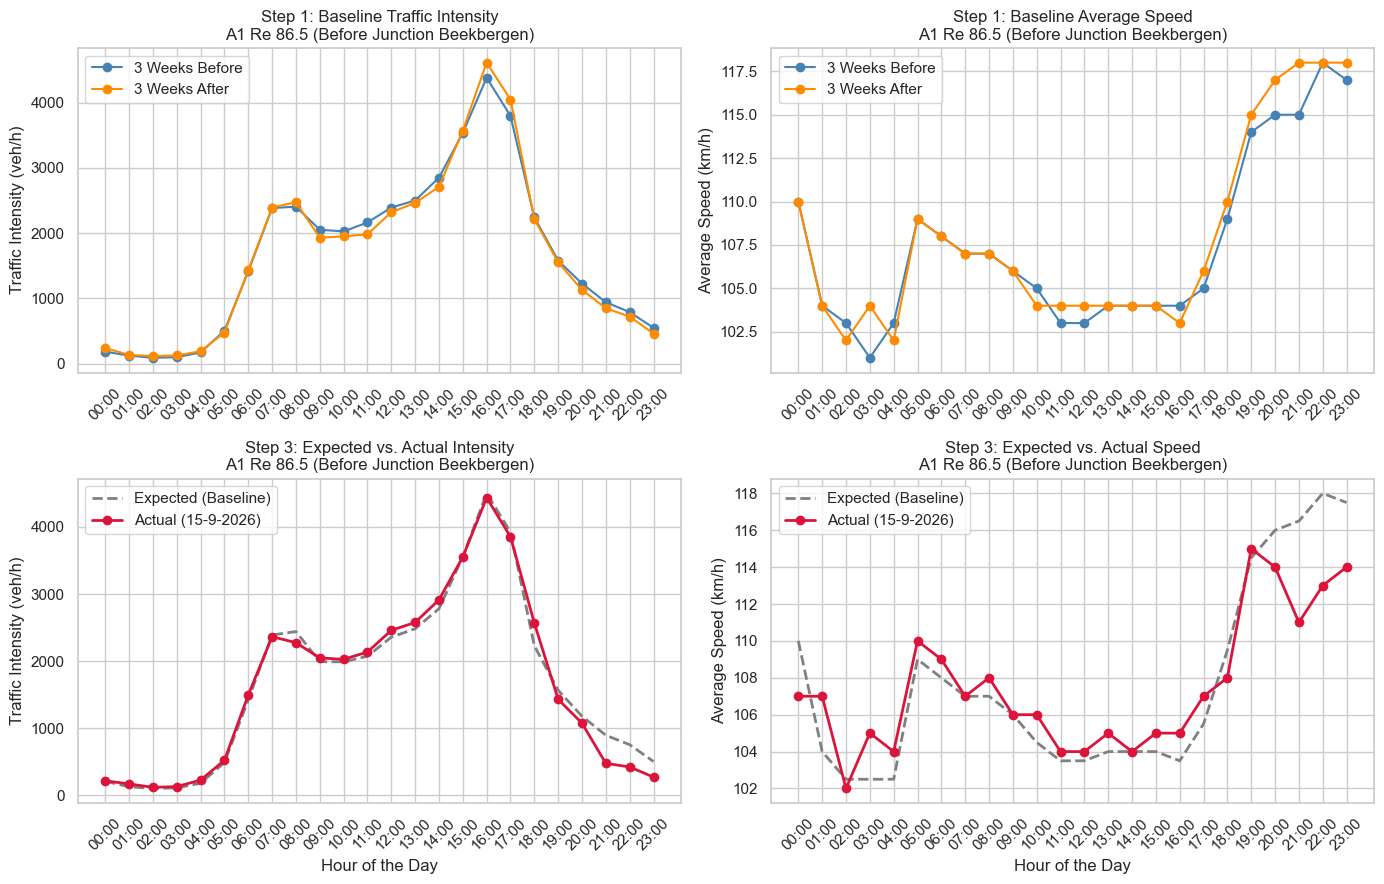

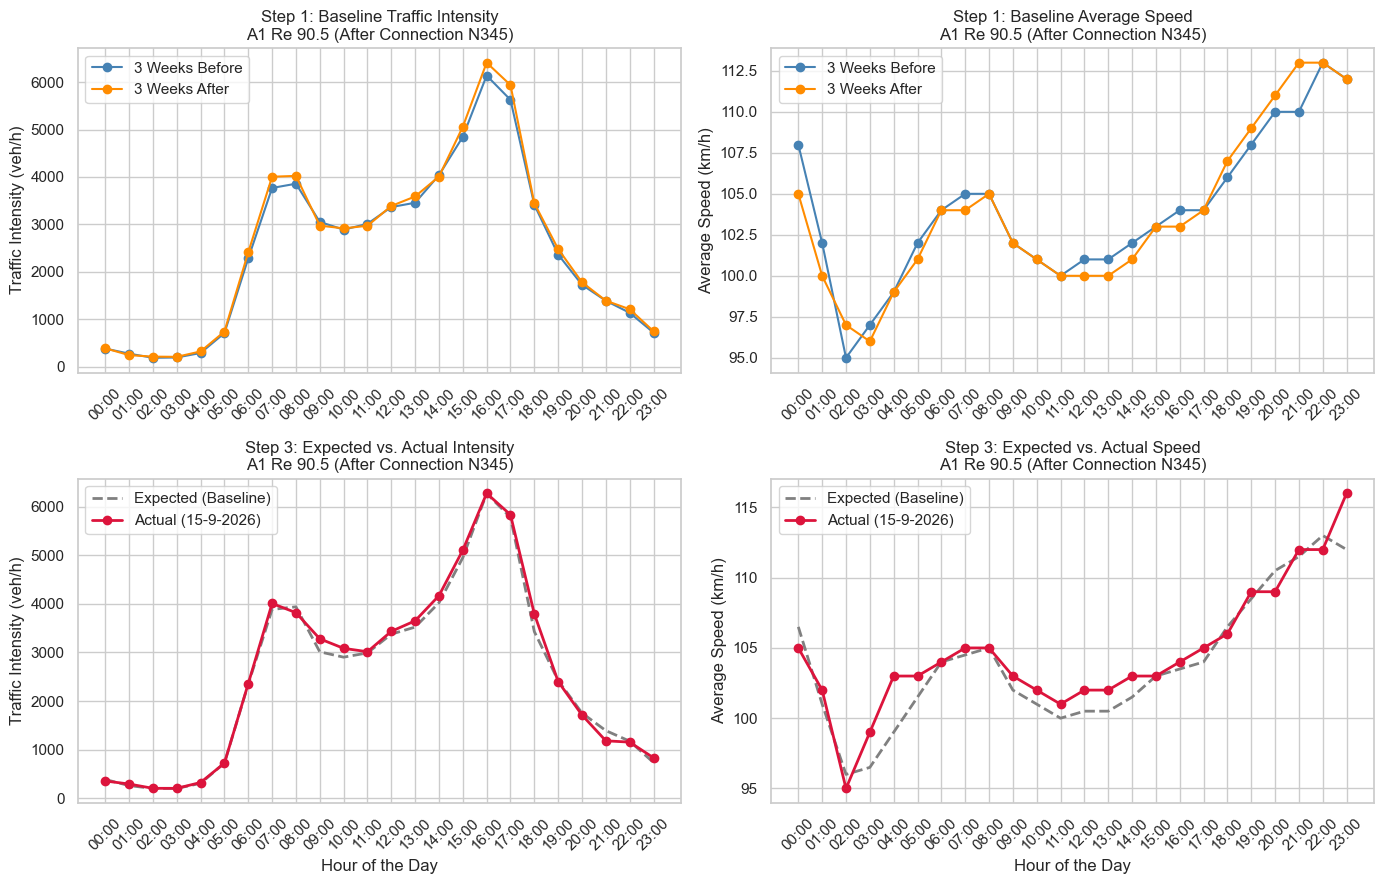

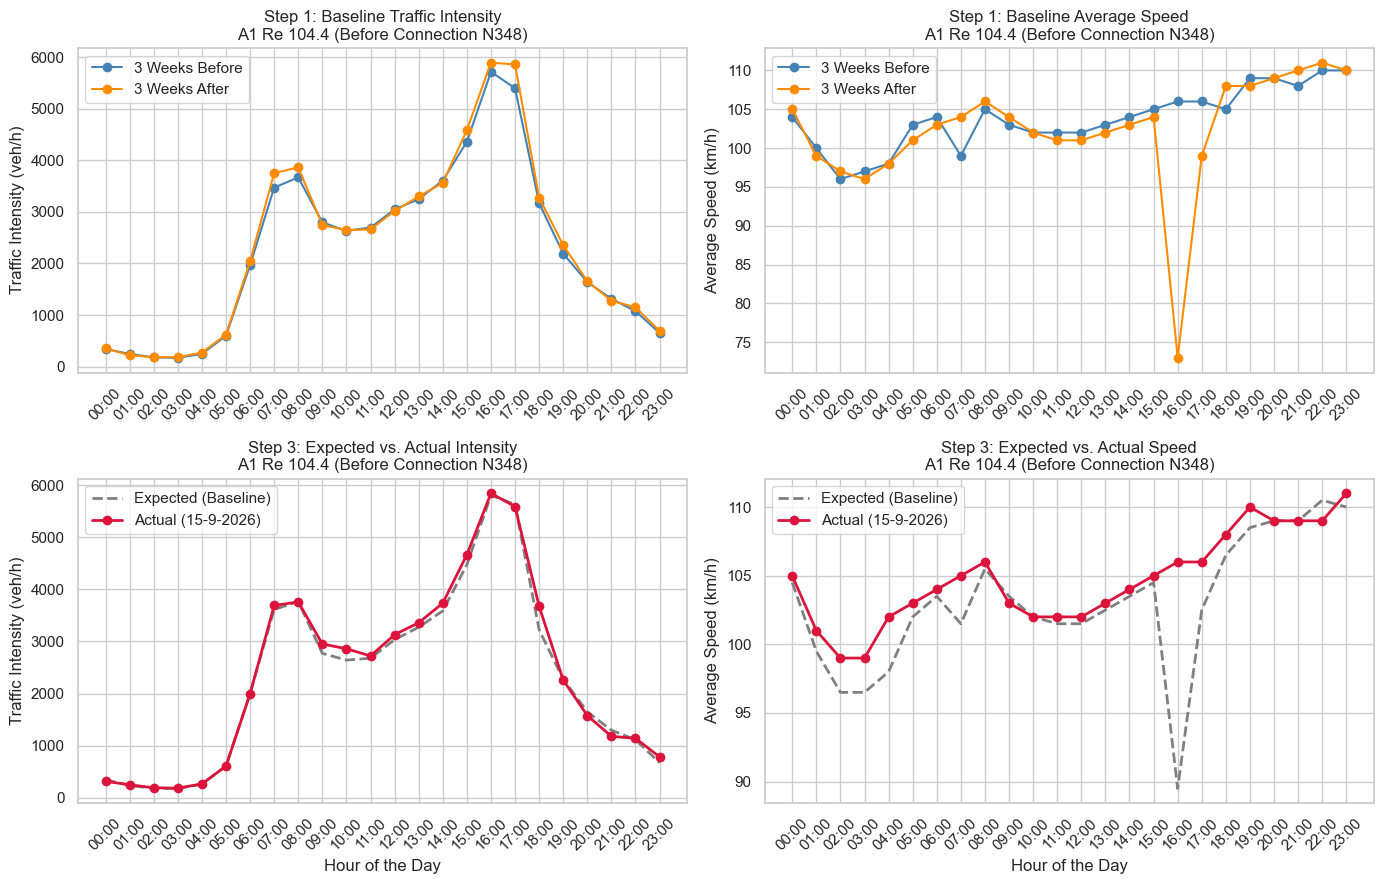

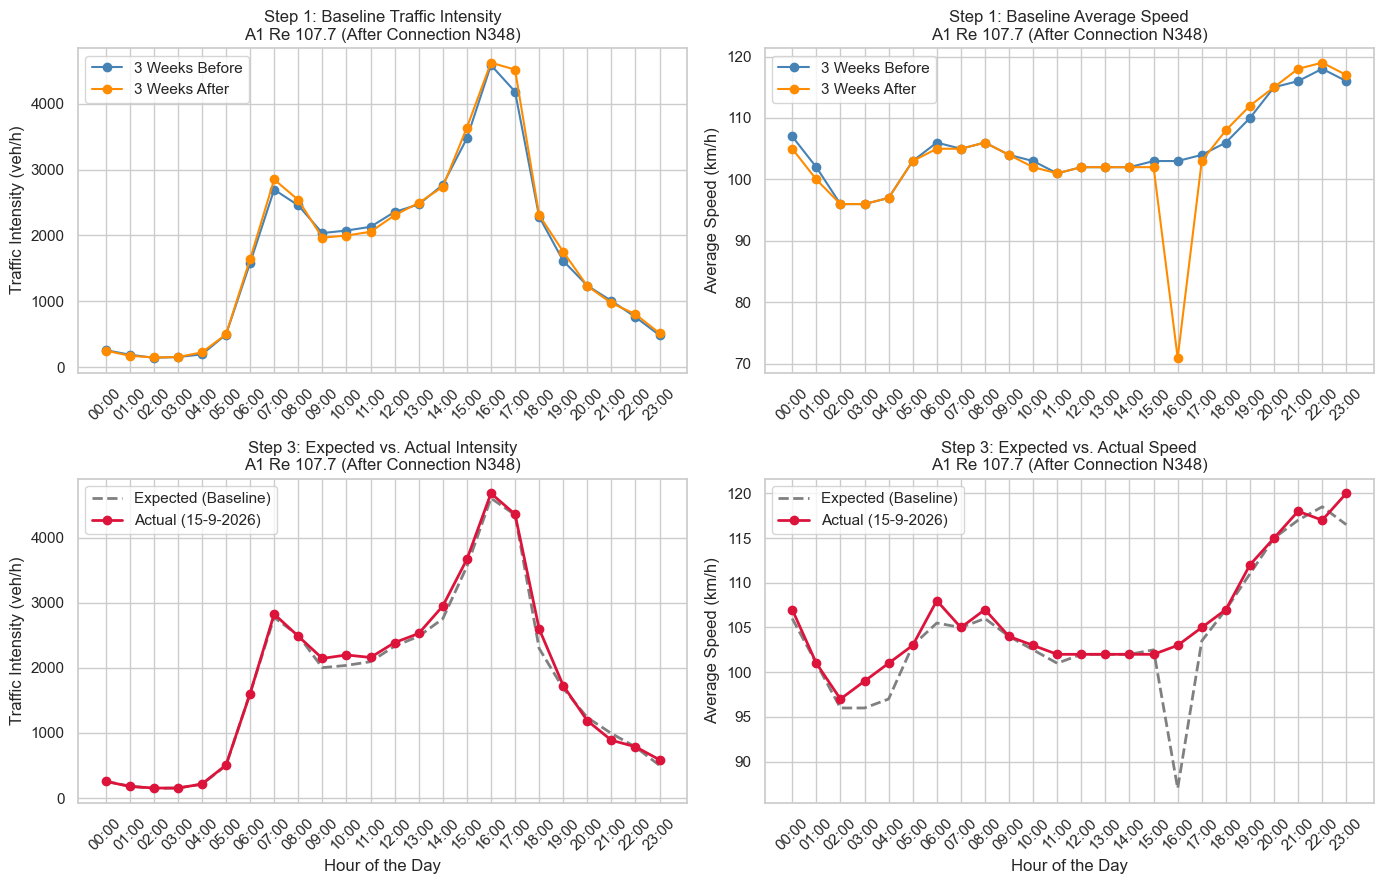

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ---------------------------------------------------------
# 1. HELPER FUNCTION: Sum Intensities & Average Speeds
# ---------------------------------------------------------
def get_location_data(file_path, sensor_list):
    # Read CSV as text using semicolon separator
    df = pd.read_csv(file_path, sep=";", header=None, dtype=str)
    row_sensors = df.iloc[1].str.strip()
    
    hours = [f"{h:02d}:00" for h in range(24)]
    total_intensity = [0.0] * 24
    total_speed = [0.0] * 24
    
    # Loop through all sensors belonging to this location
    for sensor_id in sensor_list:
        matching_cols = row_sensors[row_sensors == sensor_id].index
        
        if len(matching_cols) == 0:
            raise ValueError(f"Sensor {sensor_id} not found in {file_path}")
            
        col_int = matching_cols[0]      # Intensity column
        col_spd = matching_cols[0] + 1  # Speed column (1 column to the right)
        
        # Extract the 24 hourly rows (index 3 to 26) and convert commas to dots
        intensity = df.iloc[3:27, col_int].str.replace(",", ".").astype(float).values
        speed = df.iloc[3:27, col_spd].str.replace(",", ".").astype(float).values
        
        # Add to running totals
        total_intensity = total_intensity + intensity
        total_speed = total_speed + speed
        
    # Divide total speed by the number of sensors at this location
    avg_speed = total_speed / len(sensor_list)
    
    return pd.DataFrame({
        "Hour": hours,
        "Intensity": total_intensity,
        "Speed": avg_speed
    })

# ---------------------------------------------------------
# 2. DEFINE LOCATIONS & SENSOR IDs FOR BOTH DIRECTIONS
# ---------------------------------------------------------
# Westward (Li): Deventer -> Apeldoorn -> Amersfoort
locations_Li = {
    "A1 Li 107.6 (Before Connection N348)": ["RWS01_MONIBAS_0011hrl1076ra"],
    "A1 Li 98.7 (After Connection N348)":   ["RWS01_MONIBAS_0011hrl0987ra"],
    "A1 Li 90.6 (Before Connection N345)":  [
        "RWS01_MONIBAS_0011hrl0905ra", 
        "RWS01_MONIBAS_0011hrl0905rb"
    ],
    "A1 Li 85.6 (After Junction Beekbergen)":  ["RWS01_MONIBAS_0011hrl0851ra_1"],
    "A1 Li 46.0 (Before Junction Hoevelaken)": ["RWS01_MONIBAS_0011hrl0460ra"],
    "A1 Li 43.4 (After Junction Hoevelaken)":  ["RWS01_MONIBAS_0011hrl0434ra"]
}

# Eastward (Re): Amersfoort -> Apeldoorn -> Deventer
locations_Re = {
    "A1 Re 43.6 (Before Junction Hoevelaken)": [
        "RWS01_MONICA_00D00106CC55D007000B",
        "RWS01_MONICA_00D00106CC55D0070007",
        "RWS01_MONICA_00D00106CC55D0070087",
        "RWS01_MONICA_00D00106CC55D007008B"
    ],
    "A1 Re 46.4 (After Junction Hoevelaken)": [
        "RWS01_MONICA_10D00107400FD0070187",
        "RWS01_MONICA_10D00107400FD007000B",
        "RWS01_MONICA_10D00107400FD0070007"
    ],
    "A1 Re 86.5 (Before Junction Beekbergen)": ["RWS01_MONIBAS_0011hrr0851ra_1"],
    "A1 Re 90.5 (After Connection N345)":      ["RWS01_MONIBAS_0011hrr0905ra"],
    "A1 Re 104.4 (Before Connection N348)":    ["RWS01_MONIBAS_0011hrr1044ra"],
    "A1 Re 107.7 (After Connection N348)":     ["RWS01_MONIBAS_0011hrr1076ra"]
}

# ---------------------------------------------------------
# 3. PLOTTING FUNCTION FOR ANY DIRECTION
# ---------------------------------------------------------
def plot_direction(locations_dict, file_before, file_after, file_event):
    for location_name, sensor_list in locations_dict.items():
        # Load the data for this location
        df_before = get_location_data(file_before, sensor_list)
        df_after  = get_location_data(file_after, sensor_list)
        df_event  = get_location_data(file_event, sensor_list)
        
        # STEP 2: Calculate Expected Values (average of Before and After)
        df_expected = pd.DataFrame({
            "Hour": df_before["Hour"],
            "Expected_Intensity": (df_before["Intensity"] + df_after["Intensity"]) / 2,
            "Expected_Speed": (df_before["Speed"] + df_after["Speed"]) / 2
        })
        
        # Create a 2x2 grid: Top row = Step 1 (Baseline), Bottom row = Step 3 (Comparison)
        fig, axes = plt.subplots(2, 2, figsize=(14, 9))
        
        # --- TOP LEFT: Step 1 Baseline Intensity ---
        axes[0, 0].plot(df_before["Hour"], df_before["Intensity"], label="3 Weeks Before", color="steelblue", marker="o")
        axes[0, 0].plot(df_after["Hour"], df_after["Intensity"], label="3 Weeks After", color="darkorange", marker="o")
        axes[0, 0].set_title(f"Step 1: Baseline Traffic Intensity\n{location_name}")
        axes[0, 0].set_ylabel("Traffic Intensity (veh/h)")
        axes[0, 0].tick_params(axis="x", rotation=45)
        axes[0, 0].legend()
        
        # --- TOP RIGHT: Step 1 Baseline Speed ---
        axes[0, 1].plot(df_before["Hour"], df_before["Speed"], label="3 Weeks Before", color="steelblue", marker="o")
        axes[0, 1].plot(df_after["Hour"], df_after["Speed"], label="3 Weeks After", color="darkorange", marker="o")
        axes[0, 1].set_title(f"Step 1: Baseline Average Speed\n{location_name}")
        axes[0, 1].set_ylabel("Average Speed (km/h)")
        axes[0, 1].tick_params(axis="x", rotation=45)
        axes[0, 1].legend()
        
        # --- BOTTOM LEFT: Step 3 Expected vs Actual Intensity ---
        axes[1, 0].plot(df_expected["Hour"], df_expected["Expected_Intensity"], label="Expected (Baseline)", color="grey", linestyle="--", linewidth=2)
        axes[1, 0].plot(df_event["Hour"], df_event["Intensity"], label="Actual (15-9-2026)", color="crimson", marker="o", linewidth=2)
        axes[1, 0].set_title(f"Step 3: Expected vs. Actual Intensity\n{location_name}")
        axes[1, 0].set_xlabel("Hour of the Day")
        axes[1, 0].set_ylabel("Traffic Intensity (veh/h)")
        axes[1, 0].tick_params(axis="x", rotation=45)
        axes[1, 0].legend()
        
        # --- BOTTOM RIGHT: Step 3 Expected vs Actual Speed ---
        axes[1, 1].plot(df_expected["Hour"], df_expected["Expected_Speed"], label="Expected (Baseline)", color="grey", linestyle="--", linewidth=2)
        axes[1, 1].plot(df_event["Hour"], df_event["Speed"], label="Actual (15-9-2026)", color="crimson", marker="o", linewidth=2)
        axes[1, 1].set_title(f"Step 3: Expected vs. Actual Speed\n{location_name}")
        axes[1, 1].set_xlabel("Hour of the Day")
        axes[1, 1].set_ylabel("Average Speed (km/h)")
        axes[1, 1].tick_params(axis="x", rotation=45)
        axes[1, 1].legend()
        
        plt.tight_layout()
        plt.show()

# ---------------------------------------------------------
# 4. RUN FOR WESTWARD (Li) AND EASTWARD (Re)
# ---------------------------------------------------------
# Plot all Westward (Li) locations
plot_direction(
    locations_dict=locations_Li,
    file_before=r"C:\Users\sipke\OneDrive\schoolwerk\TIL\Y1Q1\project programming\Excel sheets\Data Dexter 15-9-2026 en 3 weken voorafagaand(voorafgaan Li).csv",
    file_after=r"C:\Users\sipke\OneDrive\schoolwerk\TIL\Y1Q1\project programming\Excel sheets\Data Dexter 15-9-2026 en 3 weken voorafagaand(Na PD Li).csv",
    file_event=r"C:\Users\sipke\OneDrive\schoolwerk\TIL\Y1Q1\project programming\Excel sheets\Data Dexter 15-9-2026 en 3 weken voorafagaand(15-9-2026 Li).csv"
)

# Plot all Eastward (Re) locations
plot_direction(
    locations_dict=locations_Re,
    file_before=r"C:\Users\sipke\OneDrive\schoolwerk\TIL\Y1Q1\project programming\Excel sheets\Data Dexter 15-9-2026 en 3 weken voorafagaand(voorafgaand Re).csv",
    file_after=r"C:\Users\sipke\OneDrive\schoolwerk\TIL\Y1Q1\project programming\Excel sheets\Data Dexter 15-9-2026 en 3 weken voorafagaand(Na PD Re).csv",
    file_event=r"C:\Users\sipke\OneDrive\schoolwerk\TIL\Y1Q1\project programming\Excel sheets\Data Dexter 15-9-2026 en 3 weken voorafagaand(15-9-2026 Re).csv"
)